In [1]:
#
# test_inv_pendulum
#

import math
import arslabrobotics as ar
import numpy as np
import scipy

# cart mass = 10 kg
# pendulum mass = 0.5 kg
# pendulum length = 0.5 m
pendulum = ar.system.InvertedPendulum(10.0, 0.5, 0.9, .5)

delta_t = 0.02

(A, B) = pendulum.discrete_state_space(delta_t)
print(A)
print(B)


[[ 1.          0.02        0.          0.        ]
 [ 0.          0.99825     0.00408333  0.        ]
 [ 0.          0.          1.          0.02      ]
 [ 0.         -0.003       0.343       1.        ]]
[[0.        ]
 [0.00194444]
 [0.        ]
 [0.00333333]]


In [2]:

Q = np.eye( 4, dtype=np.float32) * 1
R = np.eye( 1, dtype=np.float32) * 0.001

P = scipy.linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.inv(R + B.T @ P @ B) @ B.T @ P @ A

print("Optimal Gain:", K)


Optimal Gain: [[-27.74203863 -52.13126468 425.41662285 106.91192011]]


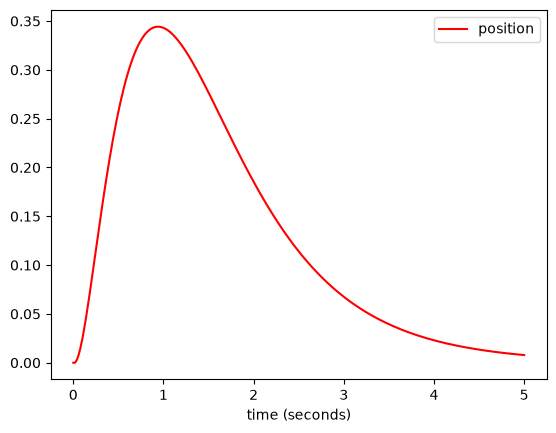

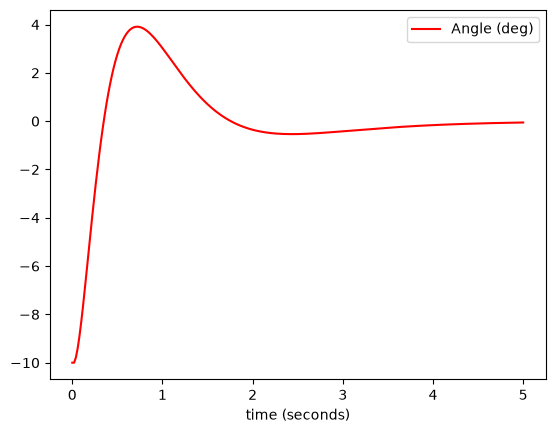

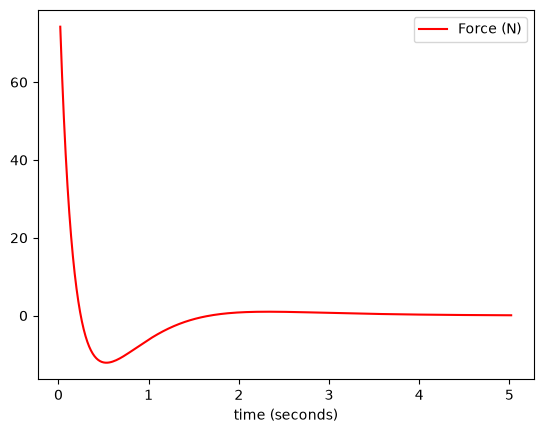

In [3]:
dpp = ar.data.DataPlotter()
dpp.set_x("time (seconds)")
dpp.add_y("pos", "position")

dpa = ar.data.DataPlotter()
dpa.set_x("time (seconds)")
dpa.add_y("angle", "Angle (deg)")

dpf = ar.data.DataPlotter()
dpf.set_x("time (seconds)")
dpf.add_y("force", "Force (N)")

pendulum.set_angle(-math.radians(10))

t = ar.utils.Time(use_fake_time = True)
t.start()
while t.get() < 5:

    (p, v, angle, omega) = pendulum.get_status()
    x = np.array([p, v, angle, omega])

    dpp.append_x(t.get())
    dpp.append_y("pos", p)
    
    dpa.append_x(t.get())
    dpa.append_y("angle", math.degrees(angle))

    #dds.wait('tick')
    t.sleep(delta_t)
    
    __delta_t = t.elapsed()

    _in = - K @ x
    _in = _in[0]

    dpf.append_x(t.get())
    dpf.append_y("force", _in)

    pendulum.evaluate(delta_t, _in)

dpp.plot()
dpa.plot()
dpf.plot()
